In [1]:
import numpy as np
import healpy as hp
import matplotlib.pylab as plt
%matplotlib inline
import rubin_sim.splat as splat
import copy 

import sqlite3
import pandas as pd
from os.path import basename

import glob

In [2]:
# Define a report element that we want to run. Needs branch maf-proto of rubin_sim to run
class AlertsperyearElement(splat.BaseReportElement):
    """Estimate how many alerts in certain years one would get
    """
    def compute_elements(self,visits_df=None, visits_array=None, nside=32, bands="ugrizy",
                         seeing_limit=1.2, n_for_template=6, years=np.arange(10)+1):
        
        times = np.arange(3653)
        metric = splat.AccumulateCountMetric(times)
        
        is_too = np.array(["ToO" in note for note in visits_array["scheduler_note"]])
        is_ddf = np.array(["DD" in note for note in visits_array["scheduler_note"]])

        count_arrays = {}
        good_seeing_count = {}
        count_subbed = {}
        alerts_years = np.zeros(years.size)
        
        for band in bands:
            indx = np.where((~is_too) & (~is_ddf) & (visits_array["visitExposureTime"] > 20) & (visits_array["band"] == band))
            sub_data = visits_array[indx]
            sl = splat.Slicer(nside=nside, missing=0)
            count_arrays[band] = sl(sub_data, metric)

            indx = np.where((~is_too) & (~is_ddf) & (visits_array["visitExposureTime"] > 20) &
                            (visits_array["band"] == band) &
                            (visits_array["seeingFwhm500"] < seeing_limit))
            sub_data = visits_array[indx]
            sl = splat.Slicer(nside=nside, missing=0)
            good_seeing_count[band] = sl(sub_data, metric)
        
            # Need to find the spot where good_seeing_count >= n_for_template
            mask = np.ones(good_seeing_count[band].shape) 
            mask[np.where(good_seeing_count[band] >= 6)] = 0
            count_masked = count_arrays[band] * mask
            count_subbed[band] = count_arrays[band] - np.max(count_masked, axis=1)[:,np.newaxis]
            count_subbed[band][np.where(count_subbed[band] < 0)] = 0

            for i,year in enumerate(years):
                alerts = count_subbed[band][:, int(365.25 * (year))] - count_subbed[band][:, int(365.25 * (year-1))]
                alerts_years[i] += np.sum(alerts)
        
        return alerts_years, count_subbed, None


In [3]:
db_files = ['baseline_v5.3.7_10yrs.db', 'three_stripes_v5.3.7_10yrs.db',
            'three_stripes_kr_v5.3.7_10yrs.db',
            'desi_tskr_v5.3.7_10yrs.db',
            'desi_stripes_delayed_v5.3.7_10yrs.db',
            'desi_stripes_v5.3.7_10yrs.db',
            "double_stripes_timing_bands_v5.3.7_10yrs.db",
            "three_stripes_or_v5.3.7_10yrs.db",
            "delay_roll_v5.3.7_10yrs.db"
            ]

In [4]:
alerts = {}
counts_subtracted = {}

for filename in db_files:
    element = AlertsperyearElement(observations=filename)
    alerts_years, counts_subbed, count_arrays, = element()
    alerts[filename.replace(".db", "")] = alerts_years
    counts_subtracted[filename.replace(".db", "")] = counts_subbed
    


In [5]:
# potential alerts / nside summed over bands?

In [6]:
for key in alerts:
    print(alerts[key][1])

397881.0
400100.0
379917.0
375212.0
394885.0
370892.0
376282.0
367141.0
398221.0


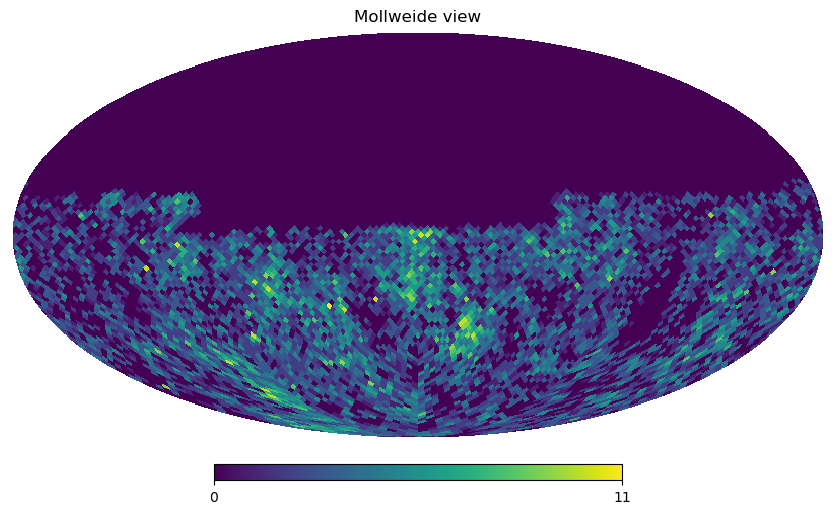

In [15]:
hp.mollview(counts_subtracted['baseline_v5.3.7_10yrs']["u"][:,365])

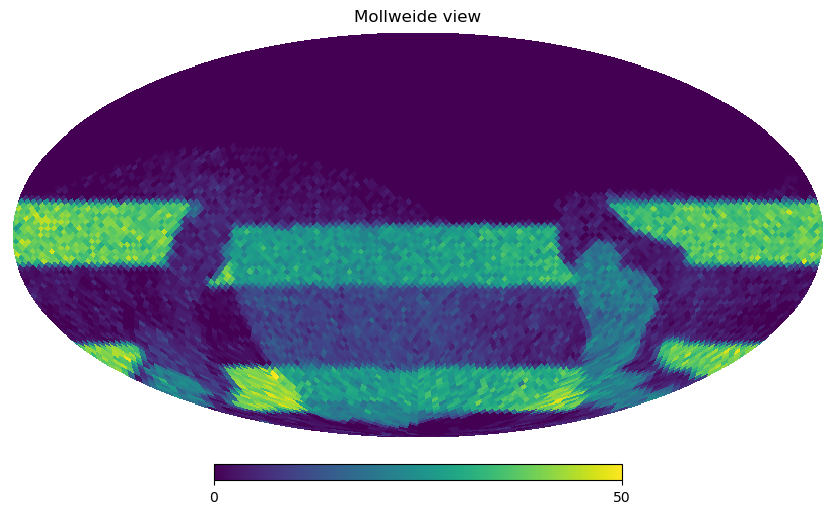

In [19]:
hp.mollview(counts_subtracted['desi_tskr_v5.3.7_10yrs']["r"][:,365*2])

In [ ]:
#maybe do area missing after N years instead, summed over band? 